# Logistic Regression Credit Classification Application Prototype
### October 2026
### By Arthur Cooper
---

This prototype is going to be used as a python web application such that users can check wheather they have good or poor credit. The model will therefore be trained on features that would be readily known to users.

In [17]:
import os
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import kagglehub


In [2]:
# Download latest version
path = kagglehub.dataset_download("parisrohan/credit-score-classification")

print("Path to dataset files:", path)

Path to dataset files: /Users/arthur/.cache/kagglehub/datasets/parisrohan/credit-score-classification/versions/1


### Read the training dataset

In [3]:
# path is the kagglehub cache folder returned by dataset_download above
# low_memory=False avoids the mixed-type warning on Monthly_Balance
train_df = pd.read_csv(os.path.join(path, 'train.csv'), low_memory=False)

print(train_df.shape)
train_df.head()

(100000, 28)


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,Good
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.45130972736786,Good
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,Good,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.48923103222177,Good


### Prepocessing
---

In [4]:
# Testing out the python pandas-dq 1.29 preprocessing and profiling library
from pandas_dq import dq_report


In [8]:
# data cleaning and preprocessing
df_cleaned = train_df.copy()

# using features known to users
keep = ['Age', 'Monthly_Inhand_Salary', 'Num_Credit_Card','Credit_History_Age', 'Num_Bank_Accounts',
        'Num_of_Loan', 'Interest_Rate', 'Outstanding_Debt', 'Amount_invested_monthly', 'Monthly_Balance',
        'Credit_Score', 'Customer_ID']
df_cleaned.drop([col for col in df_cleaned.columns if col not in keep], axis=1, inplace=True)
# This time I left customer ID in the datatset to ensure customers don't appear in both train and test sets.


# converting credit age to years
df_cleaned['Credit_History_Age'] = df_cleaned['Credit_History_Age'].str.split(' ').str[0]
df_cleaned['Credit_History_Age'] = df_cleaned['Credit_History_Age'].fillna(0)
df_cleaned['Credit_History_Age'] = df_cleaned['Credit_History_Age'].astype('int64')

# converting columns to numeric
columns_convert_num = ['Age','Num_of_Loan','Outstanding_Debt','Amount_invested_monthly','Monthly_Balance']
df_cleaned[columns_convert_num] = df_cleaned[columns_convert_num].apply(pd.to_numeric, errors='coerce')


# Numeric columns to check for outliers
numeric_columns = [col for col in df_cleaned.select_dtypes(include=[np.number]).columns if col != 'Credit_Score']

# replace outliers from the dataset using IQR method with Nan
for col in numeric_columns:
    Q1 = df_cleaned[col].quantile(0.25)
    Q3 = df_cleaned[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 3 * IQR
    upper_bound = Q3 + 3 * IQR
    df_cleaned.loc[(df_cleaned[col] < lower_bound) | (df_cleaned[col] > upper_bound), col] = np.nan

# impute missing nuemeric values with median
df_cleaned = df_cleaned.fillna(df_cleaned.median(numeric_only=True))

# drop any remaining rows with missing values
df_cleaned = df_cleaned.dropna()

# drop rows with standard credit score, as they are not useful for classification
df_cleaned = df_cleaned[df_cleaned['Credit_Score'] != 'Standard']

#remove impossible values from the dataset
df_cleaned = df_cleaned[
    (df_cleaned['Age']>0) & (df_cleaned['Age']<100) & 
    (df_cleaned['Num_Bank_Accounts']>=0) & 
    (df_cleaned['Num_of_Loan']>=0)]

# Generate a data quality report
dqr = dq_report(df_cleaned, target=None, html=False, csv_engine="pandas", verbose=1)

There are 10 duplicate rows in your dataset
    Alert: Dropping duplicate rows can sometimes cause your column data types to change to object!
    All variables classified into correct types.


/var/folders/c7/s_7n84_s6g92fqcd6c0jf1nh0000gn/T/ipykernel_98937/4036718389.py:50: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  dqr = dq_report(df_cleaned, target=None, html=False, csv_engine="pandas", verbose=1)


,Data Type,Missing Values%,Unique Values%,Minimum Value,Maximum Value,DQ Issue
Customer_ID,object,0.000000,18,,,No issue
Age,float64,0.000000,NA,14.000000,56.000000,No issue
Monthly_Inhand_Salary,float64,0.000000,NA,319.556250,15204.633333,Column has 2670 outliers greater than upper bound (10321.51) or lower than lower bound(-3449.57). Cap them or remove them.
Num_Bank_Accounts,float64,0.000000,NA,0.000000,11.000000,No issue
Num_Credit_Card,float64,0.000000,NA,0.000000,16.000000,Column has 2 outliers greater than upper bound (11.50) or lower than lower bound(-0.50). Cap them or remove them.
Interest_Rate,float64,0.000000,NA,1.000000,34.000000,No issue
Num_of_Loan,float64,0.000000,NA,0.000000,17.000000,Column has 1 outliers greater than upper bound (9.50) or lower than lower bound(-2.50). Cap them or remove them.
Outstanding_Debt,float64,0.000000,NA,0.230000,4998.070000,Column has 1249 outliers greater than upper bound (4541.68) or lower than lower bound(-1585.04). Cap them or remove them.
Credit_History_Age,float64,0.000000,NA,0.000000,33.000000,No issue
Amount_invested_monthly,float64,0.000000,NA,0.000000,730.470930,Column has 3907 outliers greater than upper bound (381.11) or lower than lower bound(-106.67). Cap them or remove them.


In [9]:
# inspect the dataset after cleaning
print(df_cleaned.info())

<class 'pandas.core.frame.DataFrame'>
Index: 46811 entries, 0 to 99999
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Customer_ID              46811 non-null  object 
 1   Age                      46811 non-null  float64
 2   Monthly_Inhand_Salary    46811 non-null  float64
 3   Num_Bank_Accounts        46811 non-null  float64
 4   Num_Credit_Card          46811 non-null  float64
 5   Interest_Rate            46811 non-null  float64
 6   Num_of_Loan              46811 non-null  float64
 7   Outstanding_Debt         46811 non-null  float64
 8   Credit_History_Age       46811 non-null  float64
 9   Amount_invested_monthly  46811 non-null  float64
 10  Monthly_Balance          46811 non-null  float64
 11  Credit_Score             46811 non-null  object 
dtypes: float64(10), object(2)
memory usage: 4.6+ MB
None


In [10]:
# inspect the dataset after cleaning
print(df_cleaned.describe())

            Age      Monthly_Inhand_Salary  Num_Bank_Accounts  \
count  46811.000000      46811.000000         46811.000000      
mean      33.153062       3979.542655             5.348465      
std       10.299748       3007.232212             2.810819      
min       14.000000        319.556250             0.000000      
25%       25.000000       1714.583333             3.000000      
50%       33.000000       3093.745000             6.000000      
75%       41.000000       5157.575000             8.000000      
max       56.000000      15204.633333            11.000000      

       Num_Credit_Card  Interest_Rate   Num_of_Loan  Outstanding_Debt  \
count   46811.000000    46811.000000   46811.000000    46811.000000     
mean        5.663690       15.372712       3.714704     1590.248843     
std         2.248513        9.635640       2.395836     1151.990204     
min         0.000000        1.000000       0.000000        0.230000     
25%         4.000000        7.000000       2.0000

In [11]:
# Check the creditscore column for class imbalance
print(df_cleaned['Credit_Score'].value_counts())

Credit_Score
Poor    28991
Good    17820
Name: count, dtype: int64


In [12]:
# convert the credit scores to numeric values for classification
credit_score_map = {'Poor': 0, 'Good': 1}
df_cleaned['Credit_Score'] = df_cleaned['Credit_Score'].map(credit_score_map)

The classes are imbalanced, so we will use stratified sampling to split the dataset into training and testing sets. We will use 80% of the data for training and 20% for testing. The random classifier also accounts for calss imbalance.

## Train 
---

In [15]:
# Train Test Split - stratified by Credit_Score and grouped by Customer_ID to avoid data leakage
df_lg = df_cleaned.copy()
# Features and target
X = df_lg.drop(['Credit_Score', 'Customer_ID'], axis=1)
y = df_lg['Credit_Score']

# Customer_ID was dropped from df_cleaned, but the index still lines up with train_df
groups = df_lg['Customer_ID']

# Train Test Split - stratified by Credit_Score and grouped by Customer_ID to avoid data leakage
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(X_train.shape, X_test.shape)


(37382, 10) (9429, 10)


In [14]:
print(y_train.shape, y_test.shape)

(37382,) (9429,)


Best params: {'logreg__C': 0.001, 'logreg__class_weight': 'balanced', 'logreg__penalty': 'l2'}
Best CV macro F1: 0.8313
              precision    recall  f1-score   support

        Poor       0.95      0.79      0.86      5850
        Good       0.73      0.93      0.82      3579

    accuracy                           0.84      9429
   macro avg       0.84      0.86      0.84      9429
weighted avg       0.87      0.84      0.85      9429

ROC AUC: 0.9107


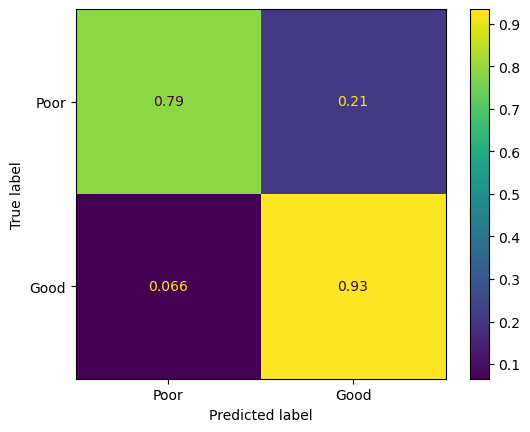

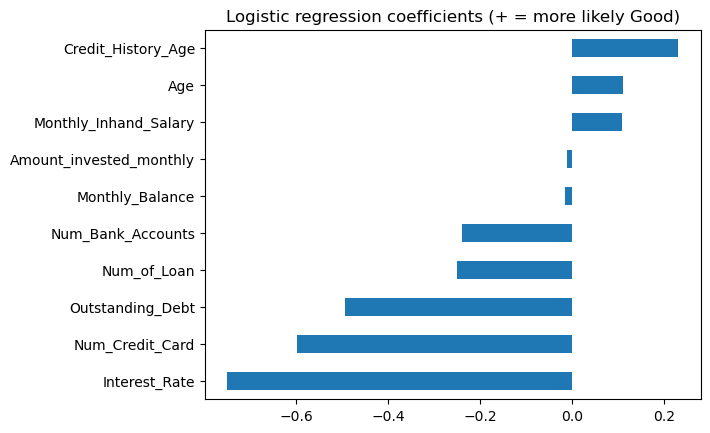

In [18]:
# Customer_ID for the training rows only - used to group the CV folds
groups_train = groups.iloc[train_idx]

# The scaler sits inside the pipeline so it is refit on each CV fold (no leakage)
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(solver='saga', max_iter=5000, random_state=42))
])

# saga supports all three penalties; l1_ratio only applies to elasticnet, so it gets its own grid
param_grid = [
    {
        'logreg__penalty': ['l1', 'l2'],
        'logreg__C': [0.001, 0.01, 0.1, 1, 10, 100],
        'logreg__class_weight': [None, 'balanced']
    },
    {
        'logreg__penalty': ['elasticnet'],
        'logreg__l1_ratio': [0.25, 0.5, 0.75],
        'logreg__C': [0.001, 0.01, 0.1, 1, 10, 100],
        'logreg__class_weight': [None, 'balanced']
    }
]

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='f1_macro', n_jobs=-1)
grid.fit(X_train, y_train, groups=groups_train)

print('Best params:', grid.best_params_)
print('Best CV macro F1:', round(grid.best_score_, 4))

# Evaluate the best model on the test set
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred, target_names=['Poor', 'Good']))
print('ROC AUC:', round(roc_auc_score(y_test, best_model.predict_proba(X_test)[:, 1]), 4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Poor', 'Good'], normalize='true')
plt.show()

# Coefficients show each feature's effect (features are scaled, so they're comparable)
coefs = pd.Series(best_model.named_steps['logreg'].coef_[0], index=X_train.columns).sort_values()
coefs.plot.barh(title='Logistic regression coefficients (+ = more likely Good)')
plt.show()


## Save model
---

In [ ]:
# Save the fitted pipeline (StandardScaler + LogisticRegression) so the Streamlit app can load
# a single object that takes raw feature values and returns predictions
import joblib

joblib.dump(best_model, 'model.pkl')
print('Saved model.pkl with features:', list(best_model.feature_names_in_))